# ПР-10 · Уровень A
**Тема:** кластеризация и сегментация клиентов (K-Means).

Данные: customers.csv (600 клиентов, без меток).

In [1]:
import sys, sklearn, numpy as np, pandas as pd, matplotlib, scipy
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, DBSCAN, AgglomerativeClustering
from sklearn.metrics import silhouette_score, adjusted_rand_score
print("Python", sys.version.split()[0], "| sklearn", sklearn.__version__,
      "| numpy", np.__version__, "| pandas", pd.__version__,
      "| matplotlib", matplotlib.__version__, "| scipy", scipy.__version__)

Python 3.14.0 | sklearn 1.9.1 | numpy 2.5.4 | pandas 3.1.0 | matplotlib 3.11.2 | scipy 1.18.1


In [2]:
# Оформление графиков (на результат не влияет)
plt.rcParams.update({"font.family": "sans-serif", "font.size": 12,
                     "font.sans-serif": ["IBM Plex Sans", "DejaVu Sans", "Arial"],
                     "figure.facecolor": "#F5F4EF", "axes.facecolor": "#F5F4EF",
                     "savefig.facecolor": "#F5F4EF", "axes.spines.top": False,
                     "axes.spines.right": False})
COLORS = np.array(["#A84C14", "#2A5DB0", "#3F8F6B", "#7A5BA6", "#C9A227", "#5C6B7A"])
NOISE = "#B8BCC2"
import os; os.makedirs("figs", exist_ok=True)

## Шаг 1. Загрузка данных

In [3]:
df = pd.read_csv("customers.csv")
features = ["avg_check", "purchases_month", "days_since_last", "discount_share"]
print(df.shape)
print(df[features].describe().round(2))

(600, 5)
       avg_check  purchases_month  days_since_last  discount_share
count     600.00           600.00           600.00          600.00
mean     2573.30             3.72            35.52            0.36
std      2010.38             3.04            38.38            0.21
min       307.00             0.10             0.00            0.00
25%       960.50             0.90             6.00            0.18
50%      1529.50             2.00            18.00            0.35
75%      4749.25             6.60            67.25            0.56
max      7270.00            10.10           149.00            0.89


## Шаг 2. Масштабирование и K-Means
Признаки в разных единицах (сомы, штуки, дни, доли), поэтому сначала масштабирую их `StandardScaler` (`fit_transform` — обучается и сразу преобразует). Число кластеров — 4.

In [4]:
X = StandardScaler().fit_transform(df[features])
km = KMeans(n_clusters=4, n_init=10, random_state=42)
df["cluster"] = km.fit_predict(X)
print(df["cluster"].value_counts().sort_index())

cluster
0     59
1    220
2    170
3    151
Name: count, dtype: int64


## Шаг 3. Рисунок на двух признаках

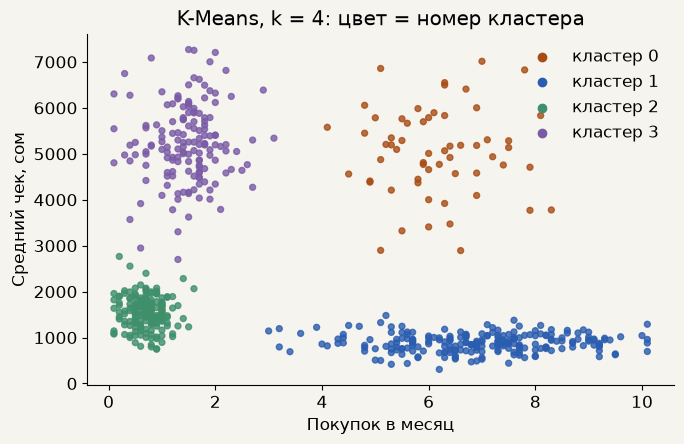

In [5]:
fig, ax = plt.subplots(figsize=(7, 4.6))
ax.scatter(df["purchases_month"], df["avg_check"], c=COLORS[df["cluster"]], s=18, alpha=0.8)
ax.set_xlabel("Покупок в месяц"); ax.set_ylabel("Средний чек, сом")
ax.set_title("K-Means, k = 4: цвет = номер кластера")
for c in range(4):
    ax.scatter([], [], c=COLORS[c], label=f"кластер {c}")
ax.legend(frameon=False)
fig.tight_layout(); fig.savefig("figs/pr10_kmeans4_scatter.png", dpi=160)
plt.show()

## Шаг 4. Профили кластеров

In [6]:
profile = df.groupby("cluster")[features].mean().round(2)
profile["clients"] = df["cluster"].value_counts().sort_index()
print(profile)

         avg_check  purchases_month  days_since_last  discount_share  clients
cluster                                                                      
0          5037.63             6.15             3.78            0.09       59
1           884.42             6.94             6.14            0.59      220
2          1543.98             0.70            91.95            0.33      170
3          5229.86             1.47            27.21            0.16      151


## Шаг 5. Опишите каждый кластер одним предложением
- Кластер 0 — «VIP-клиенты» (59 чел.): высокий средний чек (~5040 сом), часто покупают (~6 раз в месяц), были совсем недавно (~4 дня назад) и почти не берут скидки (9%) — самые ценные клиенты, их нужно удерживать.
- Кластер 1 — «Охотники за скидками» (220 чел.): маленький чек (~880 сом), но покупают чаще всех (~7 раз в месяц) и недавно, а больше половины покупок (59%) — по скидке.
- Кластер 2 — «Уходящие / спящие» (170 чел.): средний чек ~1540 сом, покупают меньше раза в месяц и не были в магазине около 3 месяцев (~92 дня) — группа риска оттока, нужна кампания по возврату.
- Кластер 3 — «Редкие крупные покупатели» (151 чел.): высокий чек (~5230 сом), но покупают редко (~1.5 раза в месяц), последняя покупка ~27 дней назад, скидками почти не пользуются (16%).